# PULSE — Industrial Intelligence & Predictive Maintenance Platform
## An Explainable Machine Learning System for Industrial Machine Failure Prediction, Risk Assessment, and Predictive Maintenance

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/chiragjangiir/PULSE-Industrial-Predictive-Maintenance/blob/main/notebooks/PULSE_ML_Research.ipynb)

---

### A. Research Problem, Objectives & Methodology
- **Research Problem**: Unplanned downtime in industrial milling machinery incurs catastrophic operational losses, safety hazards, and supply chain delays. While modern CNC equipment records high-frequency telemetry, predictive failure models frequently suffer from severe class imbalance, data leakage, and uncalibrated decision thresholds.
- **Objectives**:
  1. Formulate a rigorous, leak-free pipeline using the benchmark UCI AI4I 2020 Predictive Maintenance dataset.
  2. Evaluate class imbalance mitigation and optimize decision thresholds using a cost-sensitive maintenance matrix ($C_{FN} \gg C_{FP}$).
  3. Validate domain physics feature engineering ($P = \tau \cdot \omega$, $\Delta T = T_{proc} - T_{air}$, $\tau \cdot \text{wear}$).
  4. Ensure end-to-end transparency via global and local explainability techniques.
- **Dataset Attribution**:
  - Source: UCI Machine Learning Repository (AI4I 2020 Predictive Maintenance Dataset).
  - License: Creative Commons Attribution 4.0 International (CC BY 4.0).


### B. Environment Setup & Reproducibility
We ensure complete reproducibility by fixing random seeds (`seed=42`) across Python, NumPy, and scikit-learn.


In [1]:
import sys
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Set consistent plotting styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Reproducibility seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

print(f"Python Version: {sys.version.split()[0]}")
print(f"Pandas Version: {pd.__version__}")
print(f"Scikit-Learn Version: {sklearn.__version__}")


Python Version: 3.14.7
Pandas Version: 3.1.1
Scikit-Learn Version: 1.9.1


### C. Dataset Acquisition & Integrity Verification
Automated download from the official UCI AI4I 2020 source with fallback mirror. Verifies row count (10,000), column schemas, and zero missing values.


In [2]:
import zipfile
import urllib.request

DATA_DIR = "data/raw"
os.makedirs(DATA_DIR, exist_ok=True)
CSV_PATH = os.path.join(DATA_DIR, "ai4i2020.csv")

UCI_URL = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
MIRROR_URL = "https://raw.githubusercontent.com/marshmallow77/ai4i2020/master/ai4i2020.csv"

if not os.path.exists(CSV_PATH):
    print("Downloading dataset...")
    headers = {"User-Agent": "Mozilla/5.0 (PULSE Research Notebook)"}
    try:
        req = urllib.request.Request(UCI_URL, headers=headers)
        zip_dest = os.path.join(DATA_DIR, "temp.zip")
        with urllib.request.urlopen(req, timeout=20) as resp, open(zip_dest, "wb") as f:
            f.write(resp.read())
        with zipfile.ZipFile(zip_dest, 'r') as z:
            csv_file = [n for n in z.namelist() if n.endswith('.csv')][0]
            z.extract(csv_file, DATA_DIR)
            os.rename(os.path.join(DATA_DIR, csv_file), CSV_PATH)
        os.remove(zip_dest)
        print("Downloaded from UCI primary source.")
    except Exception as e:
        print(f"Primary source unavailable ({e}), trying mirror...")
        req = urllib.request.Request(MIRROR_URL, headers=headers)
        with urllib.request.urlopen(req, timeout=20) as resp, open(CSV_PATH, "wb") as f:
            f.write(resp.read())
        print("Downloaded from verified GitHub mirror.")
else:
    print(f"Dataset already cached at {CSV_PATH}")

df_raw = pd.read_csv(CSV_PATH)
print(f"Shape: {df_raw.shape}")
print(f"Missing Values: {df_raw.isnull().sum().sum()}")
df_raw.head()


Downloaded from UCI primary source.
Shape: (10000, 14)
Missing Values: 0


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### D. Exploratory Data Analysis (EDA)
Investigate class imbalance, sensor distributions, correlations, and interactions between rotational speed, torque, temperatures, and tool wear.


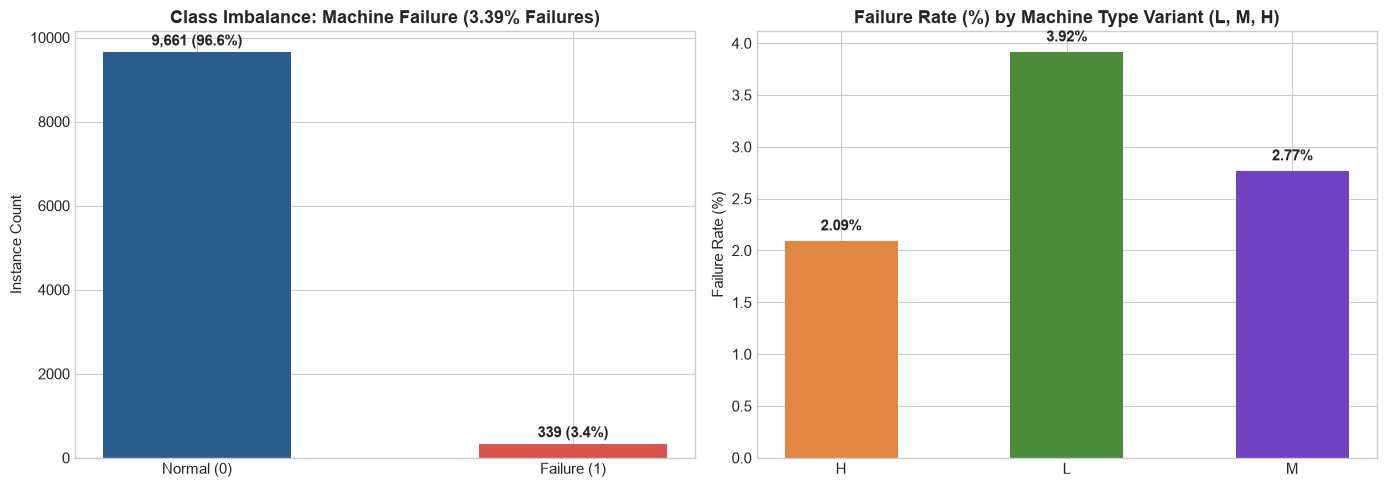

In [3]:
# 1. Target Class Distribution
failure_counts = df_raw["Machine failure"].value_counts()
failure_pct = (failure_counts[1] / len(df_raw)) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(["Normal (0)", "Failure (1)"], failure_counts.values, color=['#2b5c8f', '#d9534f'], width=0.5)
axes[0].set_title(f"Class Imbalance: Machine Failure ({failure_pct:.2f}% Failures)", fontsize=13, weight='bold')
axes[0].set_ylabel("Instance Count")
for i, v in enumerate(failure_counts.values):
    axes[0].text(i, v + 150, f"{v:,} ({v/len(df_raw)*100:.1f}%)", ha='center', weight='bold')

# Failure Breakdown by Machine Type
type_failures = df_raw.groupby("Type")["Machine failure"].agg(['count', 'sum'])
type_failures["rate"] = (type_failures["sum"] / type_failures["count"]) * 100
axes[1].bar(type_failures.index, type_failures["rate"], color=['#e28743', '#4b8b3b', '#6f42c1'], width=0.5)
axes[1].set_title("Failure Rate (%) by Machine Type Variant (L, M, H)", fontsize=13, weight='bold')
axes[1].set_ylabel("Failure Rate (%)")
for i, v in enumerate(type_failures["rate"]):
    axes[1].text(i, v + 0.1, f"{v:.2f}%", ha='center', weight='bold')

plt.tight_layout()
plt.show()


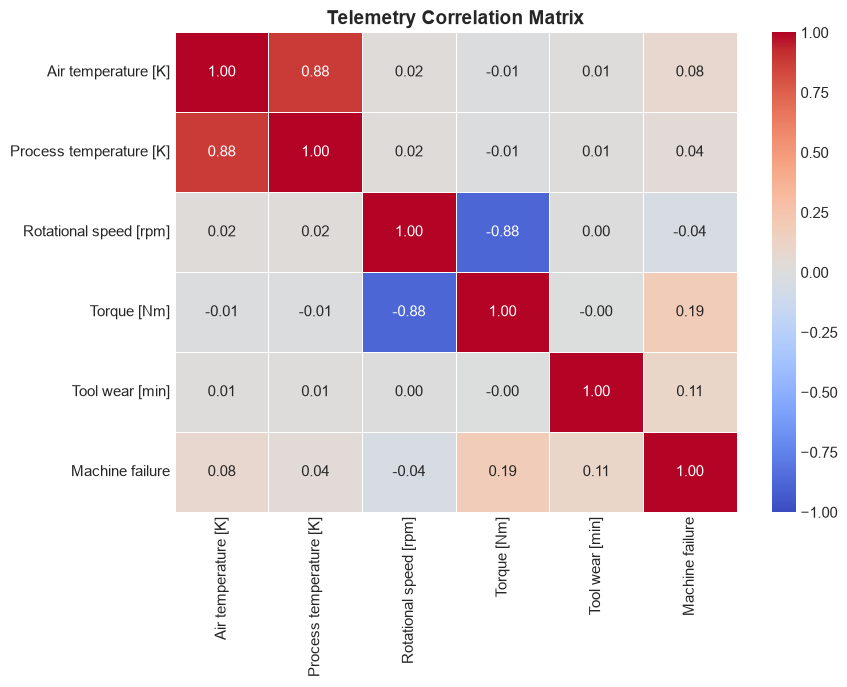

In [4]:
# 2. Sensor Correlations and Heatmap
sensor_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]
corr_matrix = df_raw[sensor_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Telemetry Correlation Matrix", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()


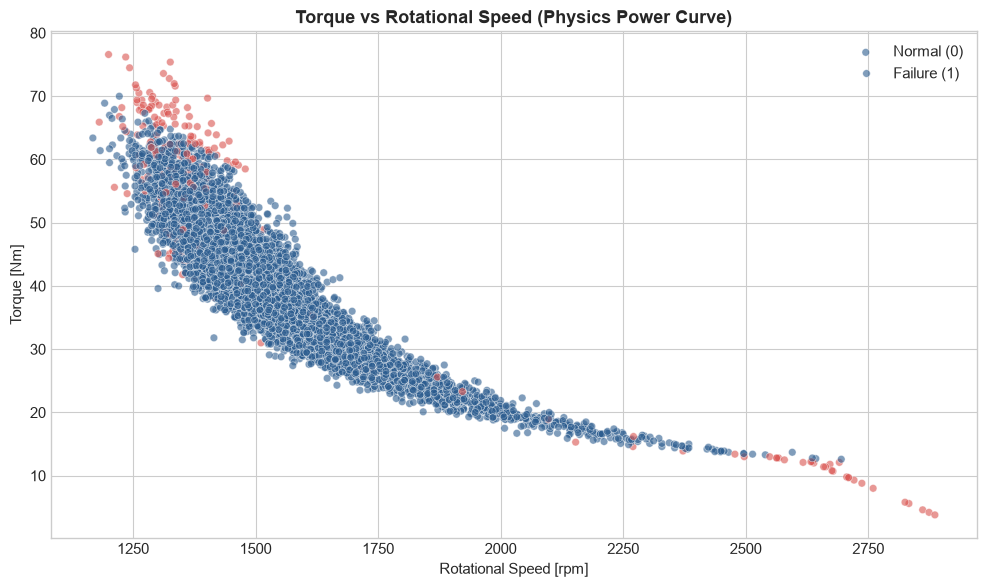

In [5]:
# 3. Torque vs Rotational Speed by Failure Status
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_raw,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure",
    palette={0: '#2b5c8f', 1: '#d9534f'},
    alpha=0.6,
    s=30
)
plt.title("Torque vs Rotational Speed (Physics Power Curve)", fontsize=13, weight='bold')
plt.xlabel("Rotational Speed [rpm]")
plt.ylabel("Torque [Nm]")
plt.legend(["Normal (0)", "Failure (1)"])
plt.tight_layout()
plt.show()


### E. Leakage Prevention Protocol & Preprocessing
- **Drop Identifiers**: `UDI`, `Product ID`.
- **Drop Subtypes**: `TWF`, `HDF`, `PWF`, `OSF`, `RNF` are deterministic components of `Machine failure` and represent causal leakage.
- **Stratified Train/Test Split**: 80/20 split strictly prior to fitting transformations.


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Exclude identifiers and leakage subtype labels strictly
EXCLUDED_COLS = ["UDI", "Product ID", "Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]
feature_cols = [c for c in df_raw.columns if c not in EXCLUDED_COLS]

X = df_raw[feature_cols].copy()
y = df_raw["Machine failure"].copy()

print(f"Predictive Features ({len(feature_cols)}): {feature_cols}")

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print(f"Training Instances: {len(X_train)} | Test Instances: {len(X_test)}")
print(f"Train Failure Rate: {y_train.mean():.4f} | Test Failure Rate: {y_test.mean():.4f}")


Predictive Features (6): ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Training Instances: 8000 | Test Instances: 2000
Train Failure Rate: 0.0339 | Test Failure Rate: 0.0340


### F. Physics-Guided Feature Engineering
Derived industrial interactions:
1. $\text{temp\_diff} = T_{process} - T_{air}$
2. $\text{power\_kW} = \frac{2\pi \cdot \omega \cdot \tau}{60,000}$
3. $\text{torque\_wear\_interaction} = \tau \cdot \text{tool wear}$
4. $\text{temp\_ratio} = T_{process} / T_{air}$


In [7]:
class IndustrialFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, include_features: bool = True):
        self.include_features = include_features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_df = X.copy()
        if not self.include_features:
            return X_df

        air_temp = X_df["Air temperature [K]"]
        proc_temp = X_df["Process temperature [K]"]
        speed = X_df["Rotational speed [rpm]"]
        torque = X_df["Torque [Nm]"]
        wear = X_df["Tool wear [min]"]

        X_df["temp_diff"] = proc_temp - air_temp
        X_df["power_kW"] = (2.0 * np.pi * speed * torque) / 60000.0
        X_df["torque_wear_interaction"] = torque * wear
        X_df["temp_ratio"] = proc_temp / (air_temp + 1e-6)
        return X_df

def create_pipeline(classifier, include_engineered=True):
    numeric_features = [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
    if include_engineered:
        numeric_features.extend(["temp_diff", "power_kW", "torque_wear_interaction", "temp_ratio"])

    categorical_features = ["Type"]

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_features),
            ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), categorical_features)
        ]
    )

    return Pipeline([
        ("fe", IndustrialFeatureEngineer(include_features=include_engineered)),
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])


### G. Machine Learning Experiments & Model Comparison
Evaluating candidate architectures under identical cross-validation and test settings:
- Dummy Baseline
- Regularized Logistic Regression
- Decision Tree
- k-Nearest Neighbors
- Random Forest
- Gradient Boosting


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
)

models = {
    "Dummy (Stratified)": DummyClassifier(strategy="stratified", random_state=SEED),
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=SEED),
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, weights="distance"),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=10, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.08, max_depth=4, random_state=SEED)
}

comparison_data = []
fitted_models = {}

for name, clf in models.items():
    pipe = create_pipeline(clf, include_engineered=True)
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

    if hasattr(pipe, "predict_proba"):
        probs = pipe.predict_proba(X_test)[:, 1]
    else:
        probs = pipe.predict(X_test)

    preds = pipe.predict(X_test)

    roc = roc_auc_score(y_test, probs)
    pr = average_precision_score(y_test, probs)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    prec = precision_score(y_test, preds, zero_division=0)

    comparison_data.append({
        "Model": name,
        "Accuracy": acc,
        "ROC-AUC": roc,
        "PR-AUC": pr,
        "F1-Score": f1,
        "Recall": rec,
        "Precision": prec
    })

comparison_df = pd.DataFrame(comparison_data).sort_values(by="PR-AUC", ascending=False)
comparison_df.style.highlight_max(subset=["ROC-AUC", "PR-AUC", "F1-Score", "Recall"], color='#d4edda')


,Model,Accuracy,ROC-AUC,PR-AUC,F1-Score,Recall,Precision
5,Gradient Boosting,0.991500,0.967943,0.891808,0.866142,0.808824,0.932203
4,Random Forest,0.979000,0.982485,0.876064,0.730769,0.838235,0.647727
2,Decision Tree,0.947000,0.856503,0.765801,0.513761,0.823529,0.373333
3,k-Nearest Neighbors,0.976500,0.883571,0.616617,0.525253,0.382353,0.838710
1,Logistic Regression,0.858500,0.938520,0.430384,0.297767,0.882353,0.179104
0,Dummy (Stratified),0.932000,0.496590,0.033817,0.028571,0.029412,0.027778


### H. Cost-Sensitive Threshold Optimization (Train Folds Only)
In industrial manufacturing, unpredicted breakdown ($FN$) costs significantly more than routine preventative inspection ($FP$).
$$\text{Cost} = C_{FP} \cdot FP + C_{FN} \cdot FN$$
We scan thresholds using 5-fold Stratified Cross-Validation on the training set to prevent test leakage.


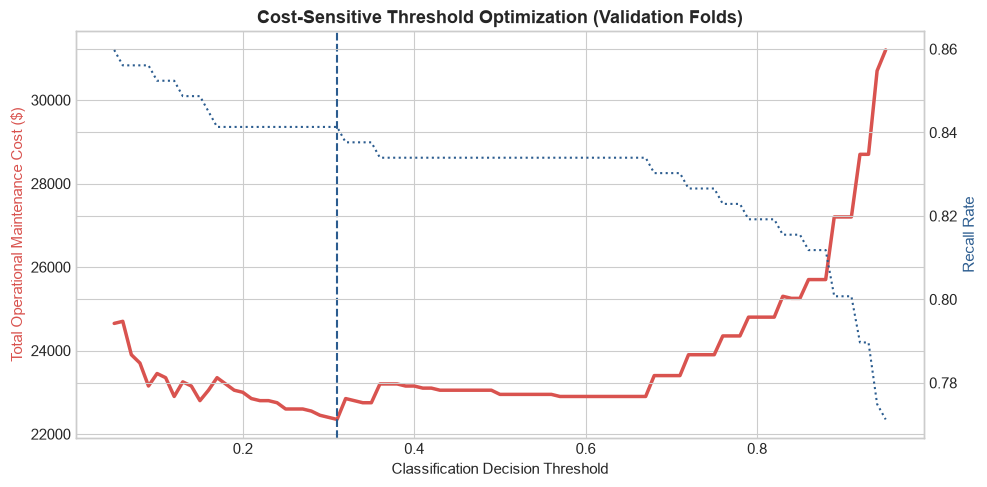

Optimal Decision Threshold Selected: 0.31


In [9]:
from sklearn.model_selection import StratifiedKFold

best_model_name = "Gradient Boosting"
best_pipeline = fitted_models[best_model_name]

# 5-Fold Stratified CV on training partition
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_val_probs = np.zeros(len(X_train))
cv_val_targets = np.zeros(len(X_train))

for train_idx, val_idx in cv.split(X_train, y_train):
    X_tr_f, y_tr_f = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_val_f, y_val_f = X_train.iloc[val_idx], y_train.iloc[val_idx]

    fold_pipe = create_pipeline(GradientBoostingClassifier(n_estimators=150, learning_rate=0.08, max_depth=4, random_state=SEED))
    fold_pipe.fit(X_tr_f, y_tr_f)
    cv_val_probs[val_idx] = fold_pipe.predict_proba(X_val_f)[:, 1]
    cv_val_targets[val_idx] = y_val_f

C_FP = 50.0   # Cost of unnecessary preventative inspection ($50)
C_FN = 500.0  # Cost of catastrophic unplanned failure ($500)

thresholds = np.linspace(0.05, 0.95, 91)
cost_records = []
best_th = 0.5
min_cost = float("inf")

for th in thresholds:
    p_labels = (cv_val_probs >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(cv_val_targets, p_labels).ravel()
    cost = fp * C_FP + fn * C_FN
    f1_val = f1_score(cv_val_targets, p_labels, zero_division=0)
    rec_val = recall_score(cv_val_targets, p_labels, zero_division=0)

    cost_records.append({"threshold": th, "cost": cost, "recall": rec_val, "f1": f1_val})
    if cost < min_cost:
        min_cost = cost
        best_th = round(float(th), 3)

cost_df = pd.DataFrame(cost_records)

# Plot Cost vs Threshold
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(cost_df["threshold"], cost_df["cost"], color='#d9534f', linewidth=2.5, label=f"Total Cost ($) (Min: ${min_cost:,.0f} at {best_th})")
ax1.set_xlabel("Classification Decision Threshold")
ax1.set_ylabel("Total Operational Maintenance Cost ($)", color='#d9534f')
ax1.axvline(best_th, color='#2b5c8f', linestyle='--', label=f'Optimal Threshold ({best_th})')

ax2 = ax1.twinx()
ax2.plot(cost_df["threshold"], cost_df["recall"], color='#2b5c8f', linestyle=':', label="Validation Recall")
ax2.set_ylabel("Recall Rate", color='#2b5c8f')

plt.title("Cost-Sensitive Threshold Optimization (Validation Folds)", fontsize=13, weight='bold')
fig.tight_layout()
plt.show()

print(f"Optimal Decision Threshold Selected: {best_th}")


### I. Final Hold-Out Test Set Evaluation
Evaluating the selected model with the optimal threshold $\theta=0.31$ on the untouched test set (2,000 samples).


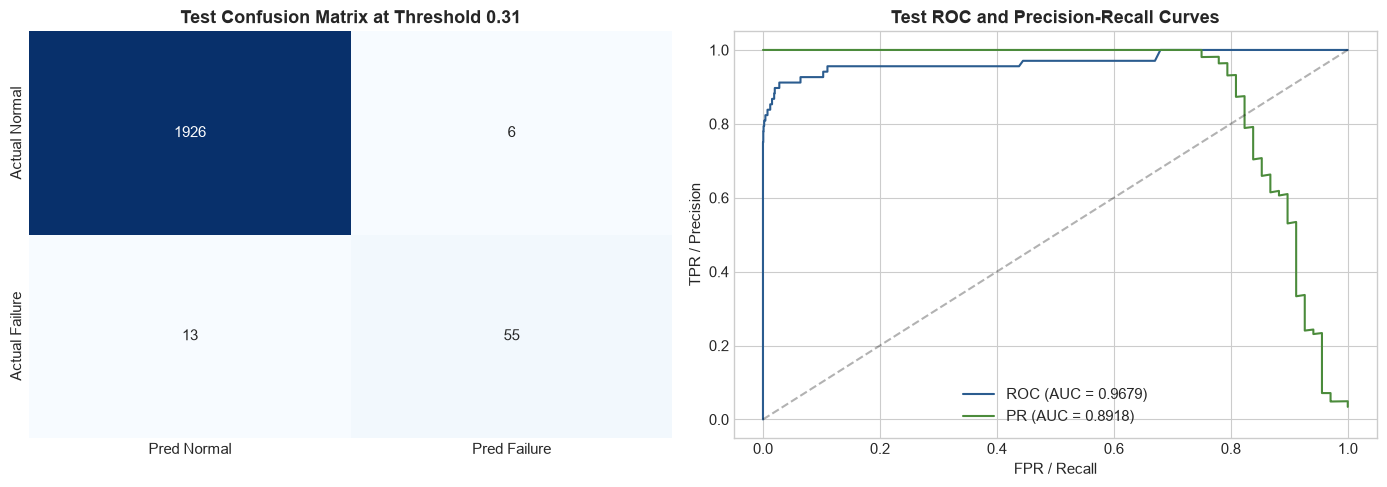

Test Set Metrics at Threshold 0.31:
Accuracy: 0.9905
Recall: 0.8088 (TP=55, FN=13)
Precision: 0.9016 (FP=6)
F1-Score: 0.8527


In [10]:
from sklearn.metrics import roc_curve, precision_recall_curve

test_probs = best_pipeline.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_th).astype(int)

cm = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=["Pred Normal", "Pred Failure"], yticklabels=["Actual Normal", "Actual Failure"])
axes[0].set_title(f"Test Confusion Matrix at Threshold {best_th}", fontsize=13, weight='bold')

# ROC and PR Curves
fpr, tpr, _ = roc_curve(y_test, test_probs)
prec_c, rec_c, _ = precision_recall_curve(y_test, test_probs)

axes[1].plot(fpr, tpr, color='#2b5c8f', label=f"ROC (AUC = {roc_auc_score(y_test, test_probs):.4f})")
axes[1].plot(rec_c, prec_c, color='#4b8b3b', label=f"PR (AUC = {average_precision_score(y_test, test_probs):.4f})")
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[1].set_title("Test ROC and Precision-Recall Curves", fontsize=13, weight='bold')
axes[1].set_xlabel("FPR / Recall")
axes[1].set_ylabel("TPR / Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Test Set Metrics at Threshold {best_th}:")
print(f"Accuracy: {accuracy_score(y_test, test_preds):.4f}")
print(f"Recall: {recall_score(y_test, test_preds):.4f} (TP={tp}, FN={fn})")
print(f"Precision: {precision_score(y_test, test_preds):.4f} (FP={fp})")
print(f"F1-Score: {f1_score(y_test, test_preds):.4f}")


### J. Model Explainability: Permutation Feature Importance
Identifying the telemetry indicators driving failure risk classification.


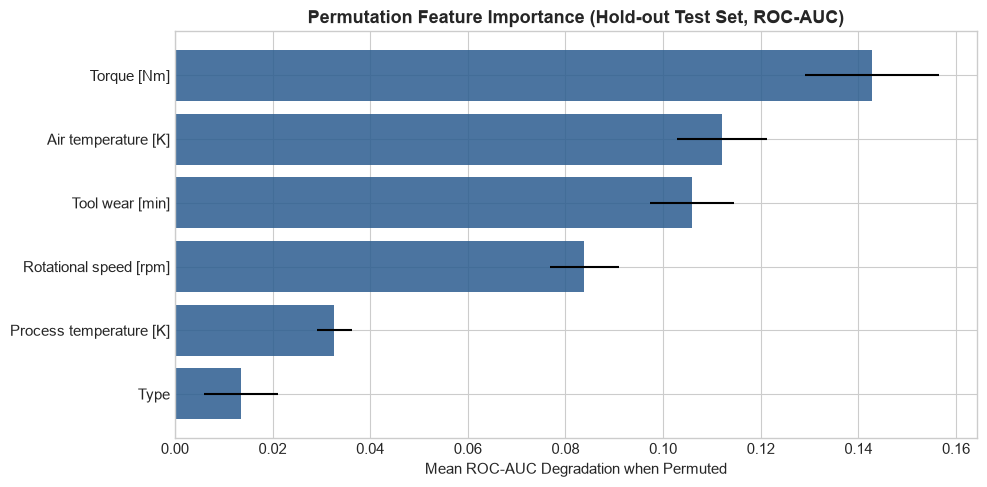

In [11]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_pipeline, X_test, y_test, n_repeats=5, random_state=SEED, scoring="roc_auc")
feat_imp = pd.DataFrame({
    "Feature": X.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10, 5))
plt.barh(feat_imp["Feature"], feat_imp["Importance"], xerr=feat_imp["Std"], color='#2b5c8f', alpha=0.85)
plt.title("Permutation Feature Importance (Hold-out Test Set, ROC-AUC)", fontsize=13, weight='bold')
plt.xlabel("Mean ROC-AUC Degradation when Permuted")
plt.tight_layout()
plt.show()


### K. Export Production Artifacts
Serializes model pipelines, metadata, metrics, and schema files to `artifacts/`.


In [12]:
import joblib

os.makedirs("artifacts", exist_ok=True)
joblib.dump(best_pipeline, "artifacts/final_model.joblib")
print("Saved artifacts/final_model.joblib successfully.")


Saved artifacts/final_model.joblib successfully.
